# Phase 3: Feature engineering (FD001)

**Goal:** turn raw sensor readings into inputs a model can learn from, without letting any future information leak in.

The feature code lives in `features/build.py` (pure functions, tested in `tests/test_features.py`). This notebook shows what each step does to the real data, and why.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)  # the feature code reads features/scaler.json relative to the project root

from features.build import (RUL_CAP, SCALER_FILE, SPLIT_FILE, add_rul, apply_scaler, build_features,
                            feature_columns, load_json)
from features.store import read_readings
from pipeline.config import SENSORS
from pipeline.db import get_engine

FIG = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")
engine = get_engine()
train = add_rul(read_readings(engine, "FD001", "train"))
split, scaler = load_json(SPLIT_FILE), load_json(SCALER_FILE)
print(f"{len(train):,} training readings from {train.unit.nunique()} engines, read from PostgreSQL")

20,631 training readings from 100 engines, read from PostgreSQL


## 3.1 The target: remaining useful life, capped at 125

**Concept:** the model predicts remaining useful life (RUL) = an engine's last cycle minus its current cycle. *Capping* sets every value above 125 to 125.

**Why:** Phase 1 showed sensors stay flat until roughly the last 100-150 cycles. With 300 cycles left or 200 cycles left, the readings look the same, so no model can tell them apart. The cap says "healthy is healthy" and lets the model focus on the part of life where wear is visible.

39% of training readings sit at the cap


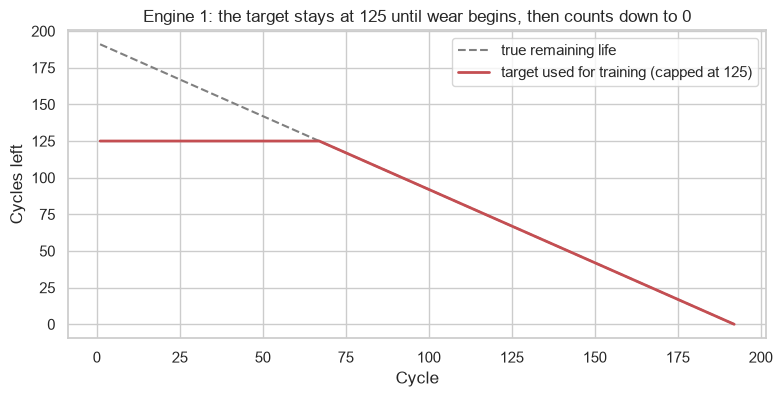

In [2]:
raw_rul = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
e = train[train.unit == 1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(e.cycle, raw_rul[e.index], "--", color="grey", label="true remaining life")
ax.plot(e.cycle, e.RUL, color="#C44E52", linewidth=2, label=f"target used for training (capped at {RUL_CAP})")
ax.set(title="Engine 1: the target stays at 125 until wear begins, then counts down to 0", xlabel="Cycle", ylabel="Cycles left")
ax.legend()
fig.savefig(FIG / "fd001_rul_target.png", dpi=150, bbox_inches="tight")
print(f"{(train.RUL == RUL_CAP).mean():.0%} of training readings sit at the cap")

## 3.2 Split by engine, not by row

**Concept:** a *validation set* is data held back to test the model during development. *Leakage* is when information about the validation data sneaks into training.

**Why:** cycle 50 and cycle 51 of one engine are almost identical. If one were in training and the other in validation, the model would look excellent while only memorising that engine. Keeping whole engines apart is the only honest test. The split is saved to `features/split.json` so every later phase uses the same engines.

In [3]:
tr_units, va_units = set(split["train"]), set(split["val"])
print(f"training engines: {len(tr_units)} | validation engines: {len(va_units)} | overlap: {len(tr_units & va_units)}")
life = train.groupby("unit")["cycle"].max()
print(f"median lifetime  training: {life[list(tr_units)].median():.0f} cycles | validation: {life[list(va_units)].median():.0f} cycles")

training engines: 80 | validation engines: 20 | overlap: 0
median lifetime  training: 199 cycles | validation: 194 cycles


## 3.3 Scale the sensors (fitted on training engines only)

**Concept:** *standardising* rescales each sensor to mean 0 and standard deviation 1. The mean and spread are learned from **training engines only** and saved to `features/scaler.json`.

**Why:** the sensors run from about 8 (s15) to about 9,000 (s9). Neural networks (Phase 5) train badly on such mixed scales. Using validation or test engines to fit the scaler would be leakage.

In [4]:
before = train[SENSORS].agg(["mean", "std"]).T.round(3)
after = apply_scaler(train[train.unit.isin(tr_units)], scaler)[SENSORS].agg(["mean", "std"]).T.round(3)
pd.concat({"raw": before, "scaled (training engines)": after}, axis=1)

raw         scaled (training engines)     
         mean     std                      mean  std
s2    642.681   0.500                      -0.0  1.0
s3   1590.523   6.131                      -0.0  1.0
s4   1408.934   9.001                      -0.0  1.0
s7    553.368   0.885                      -0.0  1.0
s8   2388.097   0.071                      -0.0  1.0
s9   9065.243  22.083                       0.0  1.0
s11    47.541   0.267                      -0.0  1.0
s12   521.413   0.738                       0.0  1.0
s13  2388.096   0.072                       0.0  1.0
s14  8143.753  19.076                       0.0  1.0
s15     8.442   0.038                      -0.0  1.0
s17   393.211   1.549                      -0.0  1.0
s20    38.816   0.181                      -0.0  1.0
s21    23.290   0.108                       0.0  1.0

## 3.4 and 3.5 Build the features

For each of the 14 sensors the code adds:

| Feature | Concept | Why it helps |
| --- | --- | --- |
| `mean5/10/20` | average of the last 5, 10, 20 cycles | smooths noise so the wear level shows |
| `std5/10/20` | spread of the last 5, 10, 20 cycles | readings often get noisier as parts wear |
| `slope5/10/20` | least-squares trend of the last 5, 10, 20 cycles | how fast the sensor is drifting = how fast the engine is degrading |
| `ema` | exponential moving average (recent cycles weigh more) | a smooth level that reacts quickly |
| `lowfreq` | FFT energy in the slowest frequencies over the last 30 cycles | separates slow drift (wear) from fast jitter (noise) |

That is 14 sensors x 12 = **168 features**. Every one is *causal*: it uses only readings up to the current cycle, so the same code works on the test set and on live data.

In [5]:
feats = build_features(train, scaler).merge(train[["unit", "cycle", "RUL"]], on=["unit", "cycle"])
print(f"{feats.shape[0]:,} rows x {len(feature_columns())} features, missing values: {int(feats[feature_columns()].isna().sum().sum())}")
feats.head(3)

20,631 rows x 168 features, missing values: 0


,unit,cycle,s2,s3,s4,s7,s8,s9,s11,s12,...,s14_lowfreq,s15_ema,s15_lowfreq,s17_ema,s17_lowfreq,s20_ema,s20_lowfreq,s21_ema,s21_lowfreq,RUL
0,1,1,-1.721670,-0.129670,-0.923428,1.124378,-0.513237,-0.847721,-0.262183,0.330513,...,0.0,-0.600546,0.0,-0.779505,0.0,1.345803,0.0,1.196623,0.0,125
1,1,2,-1.059185,0.218704,-0.640123,0.429437,-0.796334,-0.941278,-0.186920,1.174062,...,0.0,-0.540922,0.0,-0.779505,0.0,1.285154,0.0,1.204410,0.0,125
2,1,3,-0.657679,-0.410670,-0.521894,1.010453,-0.230139,-0.549836,-1.014817,1.364540,...,0.0,-0.560004,0.0,-1.014668,0.0,1.184992,0.0,1.076371,0.0,125


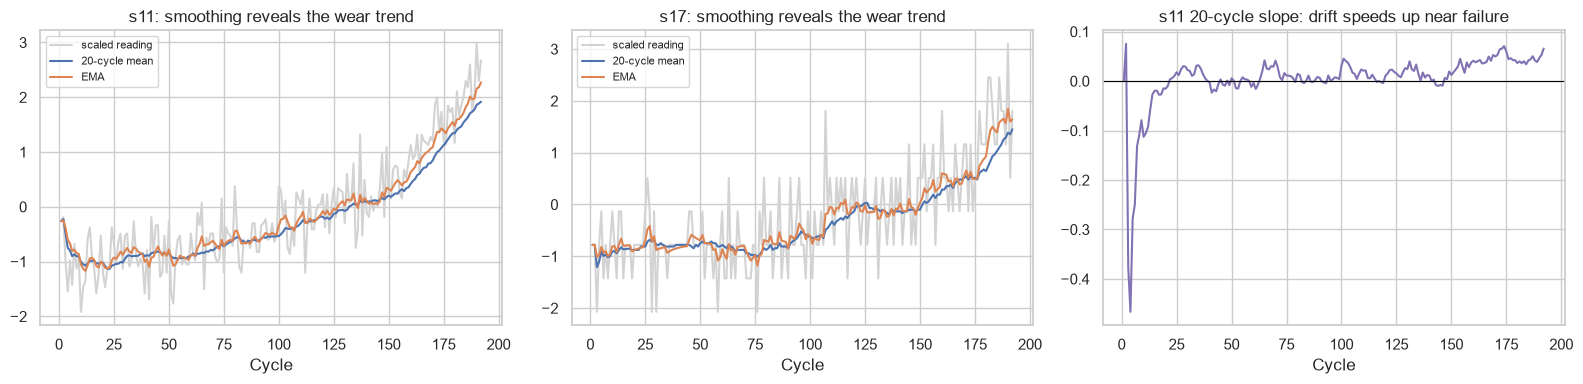

In [6]:
e = feats[feats.unit == 1]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, s in zip(axes[:2], ["s11", "s17"]):
    ax.plot(e.cycle, e[s], color="lightgrey", label="scaled reading")
    ax.plot(e.cycle, e[f"{s}_mean20"], label="20-cycle mean")
    ax.plot(e.cycle, e[f"{s}_ema"], label="EMA")
    ax.set(title=f"{s}: smoothing reveals the wear trend", xlabel="Cycle")
    ax.legend(fontsize=8)
axes[2].plot(e.cycle, e["s11_slope20"], color="#8172B3")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set(title="s11 20-cycle slope: drift speeds up near failure", xlabel="Cycle")
fig.tight_layout()
fig.savefig(FIG / "fd001_features_engine1.png", dpi=150, bbox_inches="tight")

## 3.6 Do the engineered features carry more signal than raw readings?

**Concept:** correlation with the capped RUL target, measured on training engines. Higher absolute values mean a feature tracks remaining life more closely.

**Why:** a quick sanity check that the features add information before we spend time on models. The real test is Phase 4, where models are trained with and without each feature group.

In [7]:
tr = feats[feats.unit.isin(tr_units)]
corr = tr[feature_columns() + ["RUL"]].corr()["RUL"].drop("RUL").abs()
groups = {"raw (scaled)": SENSORS}
for kind in ["mean5", "mean10", "mean20", "std20", "slope20", "ema", "lowfreq"]:
    groups[kind] = [f"{s}_{kind}" for s in SENSORS]
summary = pd.DataFrame({name: {"best |corr|": corr[cols].max(), "median |corr|": corr[cols].median()}
                        for name, cols in groups.items()}).T.round(3)
summary

,best |corr|,median |corr|
raw (scaled),0.771,0.690
mean5,0.812,0.792
mean10,0.811,0.803
mean20,0.800,0.785
std20,0.457,0.201
slope20,0.294,0.184
ema,0.811,0.803
lowfreq,0.556,0.391


s4_mean5      0.812
s17_ema       0.811
s17_mean10    0.811
s4_ema        0.810
s11_mean5     0.810
s4_mean10     0.810
s15_mean10    0.809
s15_ema       0.809
s3_ema        0.808
s3_mean10     0.808
s21_ema       0.808
s21_mean10    0.807
s20_ema       0.807
s20_mean10    0.806
s15_mean5     0.806


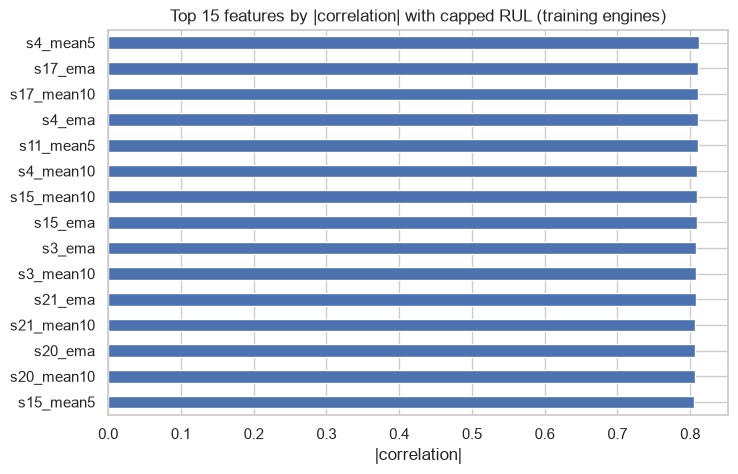

In [8]:
top = corr.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
top[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set(title="Top 15 features by |correlation| with capped RUL (training engines)", xlabel="|correlation|")
fig.savefig(FIG / "fd001_top_features.png", dpi=150, bbox_inches="tight")
print(top.round(3).to_string())

## 3.7 Features in production: built incrementally per batch

The pipeline delivers test data in shifts. `python -m features.run_features --run-id <run>` builds features **only for the readings in that run**, reading each engine's earlier history so the windows are complete. A check on the real database showed the incremental features match a full rebuild exactly, and rerunning a batch replaces its rows instead of duplicating them.

In [9]:
from sqlalchemy import text
with engine.connect() as c:
    print(pd.read_sql(text("SELECT split, COUNT(*) AS rows, COUNT(DISTINCT (engine_id, cycle)) AS unique_rows "
                           "FROM fact_features GROUP BY split"), c).to_string(index=False))

split  rows  unique_rows
 test  2500         2500
train 20631        20631


## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Built the RUL target, capped at 125 | The model needs a number to predict, and early life has no wear signal to learn from | 39% of training readings sit at the cap: much of an engine's life looks "healthy" | Phase 4 scores test predictions against labels capped the same way, and says so |
| 2 | Split 80 / 20 by engine, saved to `split.json` | Rows from one engine are near-duplicates; splitting rows would let the model cheat | The two groups have similar lifetimes, so validation is a fair stand-in for unseen engines | Every later phase tunes on the same 20 validation engines and touches the test set once |
| 3 | Fitted the scaler on training engines only | Sensors differ by up to 1,000x in scale; fitting on other engines would leak | After scaling, training sensors have mean 0 and spread 1 | Phase 5 neural networks get well-scaled inputs |
| 4 | Added rolling mean, spread and slope | Single readings are noisy; trends over 5-20 cycles show wear and its speed | Smoothed means lift the median sensor correlation from 0.69 (raw) to 0.80; slopes and spreads are weak on their own (0.18-0.20) | Phase 4 compares XGBoost on raw readings vs these features |
| 5 | Added EMA and FFT low-frequency energy | Basic signal-processing tools: separate slow drift from noise | EMA matches the best rolling means (0.80); FFT energy is weaker (median 0.39), as expected with one reading per cycle | Phase 4 retrains without them to measure whether they really help |
| 6 | Built features incrementally per pipeline run | Production systems only process newly arrived data | Incremental features equal a full rebuild exactly; reruns do not duplicate | Phase 7 (Prefect) calls the same function after each shift |
| 7 | Wrote 8 tests (causality, no engine mixing, scaler, slope, incremental) | Leakage bugs are silent: the model just looks too good | All pass; the causality test proves no feature looks into the future | CI guards these rules on every push |

**The habit to keep:** every feature must be computable at prediction time from data that exists at that moment. If you cannot compute it live, you cannot use it in training.